In [ ]:
# Last.fm 1K — Dataset Analysis

## Project: Music Discovery with Contextual Multi-Armed Bandits

This notebook performs the exploratory data analysis (EDA) of the Last.fm 1K dataset.

The goal is to characterize the dataset before defining the Contextual Multi-Armed Bandit formulation.

In particular, we analyze:

- dataset structure and schema;
- number of listening events, users, artists, and tracks;
- user activity and listening behavior;
- artist and track popularity;
- temporal distribution of listening events;
- repeated listening behavior;
- missing identifiers and metadata quality;
- implications for candidate generation, context, reward design, and sequential offline evaluation.

The analysis is exploratory and does not modify the original dataset.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Environment ready.")

Environment ready.


In [3]:
# Project root
PROJECT_ROOT = Path.cwd().parent

# Dataset directory
DATASET_DIR = PROJECT_ROOT / "Dataset" / "lastfm-dataset-1K"

# Dataset files
LISTENING_FILE = DATASET_DIR / "userid-timestamp-artid-artname-traid-traname.tsv"
PROFILE_FILE = DATASET_DIR / "userid-profile.tsv"

print("Dataset directory:", DATASET_DIR)
print("Listening file exists:", LISTENING_FILE.exists())
print("Profile file exists:", PROFILE_FILE.exists())

Dataset directory: C:\Users\dales\OneDrive\Desktop\PROGETTO SII\music-discovery-CMAB\Dataset\lastfm-dataset-1K
Listening file exists: True
Profile file exists: True


In [4]:
print(f"Listening file size: {LISTENING_FILE.stat().st_size / (1024**3):.2f} GB")
print(f"Profile file size: {PROFILE_FILE.stat().st_size / (1024**2):.2f} MB")

Listening file size: 2.36 GB
Profile file size: 0.04 MB


In [ ]:
## 1. Dataset schema

The main listening-history file contains one row per listening event.

The columns are:

- `user_id`: anonymized user identifier;
- `timestamp`: UTC timestamp of the listening event;
- `artist_id`: MusicBrainz artist identifier;
- `artist_name`: artist name;
- `track_id`: MusicBrainz track identifier;
- `track_name`: track name.

The profile file contains additional user-level information such as gender, age, country, and registration date.

In [5]:
LISTENING_COLUMNS = [
    "user_id",
    "timestamp",
    "artist_id",
    "artist_name",
    "track_id",
    "track_name",
]

PROFILE_COLUMNS = [
    "user_id",
    "gender",
    "age",
    "country",
    "registered",
]

In [6]:
sample_df = pd.read_csv(
    LISTENING_FILE,
    sep="\t",
    header=None,
    names=LISTENING_COLUMNS,
    nrows=100_000,
    encoding="utf-8",
)

sample_df.head()

,user_id,timestamp,artist_id,artist_name,track_id,track_name
0,user_000001,2009-05-04T23:08:57Z,f1b1cf71-bd35-4e99-8624-24a6e15f133a,Deep Dish,NaN,Fuck Me Im Famous (Pacha Ibiza)-09-28-2007
1,user_000001,2009-05-04T13:54:10Z,a7f7df4a-77d8-4f12-8acd-5c60c93f4de8,坂本龍一,NaN,Composition 0919 (Live_2009_4_15)
2,user_000001,2009-05-04T13:52:04Z,a7f7df4a-77d8-4f12-8acd-5c60c93f4de8,坂本龍一,NaN,Mc2 (Live_2009_4_15)
3,user_000001,2009-05-04T13:42:52Z,a7f7df4a-77d8-4f12-8acd-5c60c93f4de8,坂本龍一,NaN,Hibari (Live_2009_4_15)
4,user_000001,2009-05-04T13:42:11Z,a7f7df4a-77d8-4f12-8acd-5c60c93f4de8,坂本龍一,NaN,Mc1 (Live_2009_4_15)


In [7]:
sample_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   user_id      100000 non-null  str  
 1   timestamp    100000 non-null  str  
 2   artist_id    97229 non-null   str  
 3   artist_name  100000 non-null  str  
 4   track_id     88189 non-null   str  
 5   track_name   100000 non-null  str  
dtypes: str(6)
memory usage: 4.6 MB


In [8]:
sample_df.describe(include="all")

,user_id,timestamp,artist_id,artist_name,track_id,track_name
count,100000,100000,97229,100000,88189,100000
unique,4,99601,3082,3407,15337,16853
top,user_000002,2009-02-09T04:12:56Z,82b304c0-7da4-45d3-896a-0767c7ae1141,The Libertines,ebb5863c-cd2f-45db-8c88-e1ec1ef64ee7,Black Is The Colour
freq,57438,3,2411,2411,222,295


In [9]:
# Convert timestamp to datetime
sample_df["timestamp"] = pd.to_datetime(
    sample_df["timestamp"],
    utc=True,
    errors="coerce"
)

print("Invalid timestamps:", sample_df["timestamp"].isna().sum())
print("Start:", sample_df["timestamp"].min())
print("End:", sample_df["timestamp"].max())

Invalid timestamps: 0
Start: 2005-10-30 22:23:21+00:00
End: 2009-05-04 23:08:57+00:00


In [10]:
# Missing values
missing = sample_df.isna().sum()

missing_percentage = (
    sample_df.isna().mean() * 100
).round(2)

missing_summary = pd.DataFrame({
    "missing_count": missing,
    "missing_percentage": missing_percentage
})

missing_summary

,missing_count,missing_percentage
user_id,0,0.00
timestamp,0,0.00
artist_id,2771,2.77
artist_name,0,0.00
track_id,11811,11.81
track_name,0,0.00


In [11]:
# Number of unique values
unique_summary = sample_df.nunique().sort_values(ascending=False)

unique_summary

timestamp      99601
track_name     16853
track_id       15337
artist_name     3407
artist_id       3082
user_id            4
dtype: int64

In [12]:
chunksize=500_000

In [ ]:
## 2. Analisi dell'intero dataset

The exploratory analysis is now extended to the complete Last.fm 1K listening history.

Since the main file contains approximately 19 million listening events and occupies more than 2 GB on disk, the dataset is processed incrementally using chunks.

This approach allows us to compute global statistics without loading the complete dataset into memory at once.


In [19]:
# Test raw TSV parsing

rows_checked = 0
valid_rows = 0
bad_rows = []

with open(LISTENING_FILE, "r", encoding="utf-8", errors="replace") as f:
    for line_number, line in enumerate(f, start=1):

        fields = line.rstrip("\n\r").split("\t")

        rows_checked += 1

        if len(fields) == 6:
            valid_rows += 1
        else:
            bad_rows.append((line_number, len(fields), line))

        if rows_checked >= 100_000:
            break

print("Rows checked:", rows_checked)
print("Valid rows:", valid_rows)
print("Malformed rows:", len(bad_rows))

if bad_rows:
    print("\nFirst malformed rows:")
    for row in bad_rows[:5]:
        print(row[0], "->", row[1], "fields")
        print(repr(row[2]))

Rows checked: 100000
Valid rows: 100000
Malformed rows: 0


In [21]:
# Full structural validation of the TSV file

total_lines = 0
valid_lines = 0
malformed_lines = 0

malformed_examples = []

with open(
    LISTENING_FILE,
    "r",
    encoding="utf-8",
    errors="replace"
) as f:

    for line_number, line in enumerate(f, start=1):

        total_lines += 1

        fields = line.rstrip("\n\r").split("\t")

        if len(fields) == 6:
            valid_lines += 1
        else:
            malformed_lines += 1

            if len(malformed_examples) < 10:
                malformed_examples.append(
                    (line_number, len(fields), line)
                )


print("===== STRUCTURAL VALIDATION =====")
print(f"Total lines:      {total_lines:,}")
print(f"Valid lines:      {valid_lines:,}")
print(f"Malformed lines:  {malformed_lines:,}")

if malformed_examples:
    print("\n===== FIRST MALFORMED LINES =====")

    for line_number, field_count, line in malformed_examples:
        print(f"\nLine {line_number:,} -> {field_count} fields")
        print(repr(line))
else:
    print("\nNo malformed lines found.")

===== STRUCTURAL VALIDATION =====
Total lines:      19,150,868
Valid lines:      19,150,868
Malformed lines:  0

No malformed lines found.


In [22]:
from collections import defaultdict

# Global user statistics
user_event_count = defaultdict(int)
user_artist_count = defaultdict(set)
user_track_count = defaultdict(set)

user_first_timestamp = {}
user_last_timestamp = {}

missing_artist_by_user = defaultdict(int)
missing_track_by_user = defaultdict(int)

with open(
    LISTENING_FILE,
    "r",
    encoding="utf-8",
    errors="replace"
) as f:

    for line_number, line in enumerate(f, start=1):

        user_id, timestamp, artist_id, artist_name, track_id, track_name = (
            line.rstrip("\n\r").split("\t")
        )

        user_event_count[user_id] += 1

        # Artist / track identifiers
        if artist_id:
            user_artist_count[user_id].add(artist_id)
        else:
            missing_artist_by_user[user_id] += 1

        if track_id:
            user_track_count[user_id].add(track_id)
        else:
            missing_track_by_user[user_id] += 1

        # Timestamp
        timestamp = pd.Timestamp(timestamp)

        if (
            user_id not in user_first_timestamp
            or timestamp < user_first_timestamp[user_id]
        ):
            user_first_timestamp[user_id] = timestamp

        if (
            user_id not in user_last_timestamp
            or timestamp > user_last_timestamp[user_id]
        ):
            user_last_timestamp[user_id] = timestamp

        if line_number % 1_000_000 == 0:
            print(f"Processed: {line_number:,}")

Processed: 1,000,000
Processed: 2,000,000
Processed: 3,000,000
Processed: 4,000,000
Processed: 5,000,000
Processed: 6,000,000
Processed: 7,000,000
Processed: 8,000,000
Processed: 9,000,000
Processed: 10,000,000
Processed: 11,000,000
Processed: 12,000,000
Processed: 13,000,000
Processed: 14,000,000
Processed: 15,000,000
Processed: 16,000,000
Processed: 17,000,000
Processed: 18,000,000
Processed: 19,000,000


In [23]:
user_stats = pd.DataFrame({
    "user_id": list(user_event_count.keys()),
    "n_events": [
        user_event_count[u]
        for u in user_event_count
    ],
    "n_artists": [
        len(user_artist_count[u])
        for u in user_event_count
    ],
    "n_tracks": [
        len(user_track_count[u])
        for u in user_event_count
    ],
    "missing_artist_id": [
        missing_artist_by_user[u]
        for u in user_event_count
    ],
    "missing_track_id": [
        missing_track_by_user[u]
        for u in user_event_count
    ],
    "first_timestamp": [
        user_first_timestamp[u]
        for u in user_event_count
    ],
    "last_timestamp": [
        user_last_timestamp[u]
        for u in user_event_count
    ],
})

user_stats.head()

,user_id,n_events,n_artists,n_tracks,missing_artist_id,missing_track_id,first_timestamp,last_timestamp
0,user_000001,16685,578,2325,1263,4735,2006-08-13 13:59:20+00:00,2009-05-04 23:08:57+00:00
1,user_000002,57438,1211,7701,708,4009,2006-02-24 18:05:42+00:00,2009-04-28 18:41:35+00:00
2,user_000003,19494,840,4075,421,1942,2005-10-30 22:23:21+00:00,2009-05-04 10:29:04+00:00
3,user_000004,18411,1623,5409,770,2089,2007-04-19 19:15:15+00:00,2009-04-30 16:30:20+00:00
4,user_000005,20341,847,1378,2221,4941,2006-08-12 16:36:44+00:00,2009-05-04 21:54:33+00:00


In [24]:
print("Number of users:", len(user_stats))
user_stats.describe()

Number of users: 992


,n_events,n_artists,n_tracks,missing_artist_id,missing_track_id
count,992.000000,992.000000,992.000000,992.000000,992.000000
mean,19305.310484,826.663306,3995.151210,607.022177,2186.076613
std,23210.400389,860.361005,4682.570444,1203.620364,3533.968979
min,2.000000,1.000000,2.000000,0.000000,0.000000
25%,3774.250000,286.750000,1158.250000,58.000000,342.000000
50%,11551.000000,546.500000,2717.500000,226.000000,1064.500000
75%,25707.750000,1053.500000,5170.000000,642.250000,2624.250000
max,183103.000000,7809.000000,59850.000000,15008.000000,44657.000000


In [ ]:
## 3. User activity

The distribution of listening activity is analyzed to characterize differences in the amount of historical information available for each user.

This analysis is particularly relevant for the sequential recommendation setting, since users with longer histories provide more observations for modeling preferences and simulating the exploration–exploitation process.


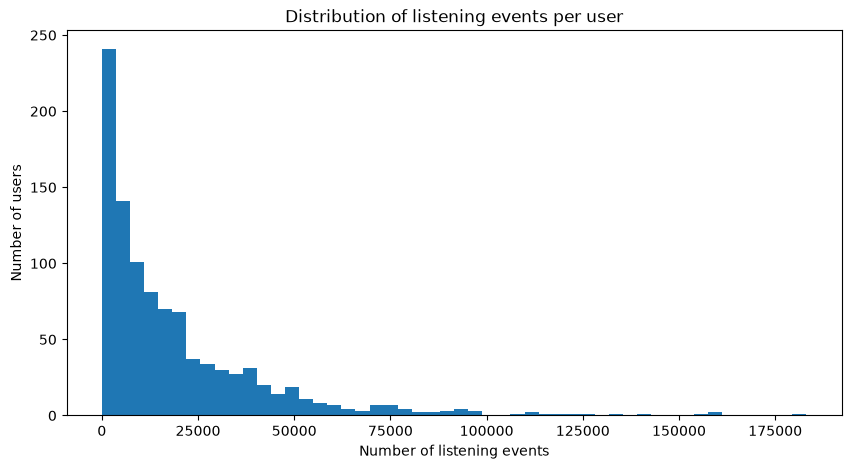

In [25]:
plt.figure(figsize=(10, 5))

plt.hist(
    user_stats["n_events"],
    bins=50
)

plt.xlabel("Number of listening events")
plt.ylabel("Number of users")
plt.title("Distribution of listening events per user")

plt.show()

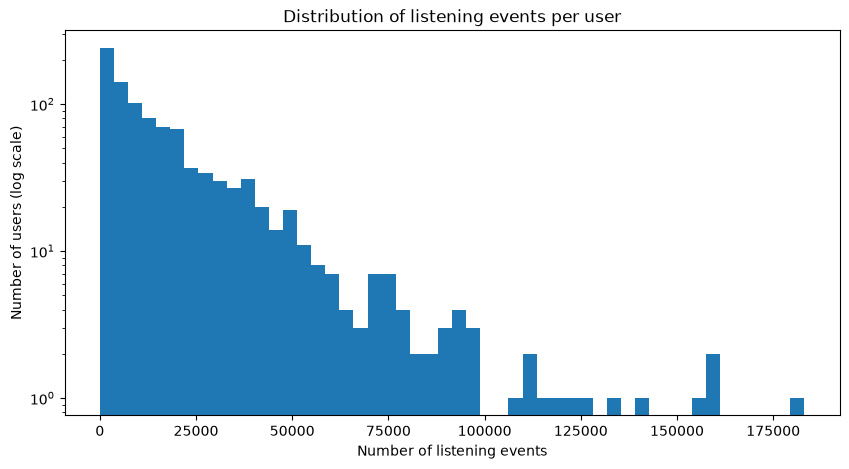

In [26]:
plt.figure(figsize=(10, 5))

plt.hist(
    user_stats["n_events"],
    bins=50,
    log=True
)

plt.xlabel("Number of listening events")
plt.ylabel("Number of users (log scale)")
plt.title("Distribution of listening events per user")

plt.show()

In [ ]:
## 4. User history richness

The number of listening events alone does not fully describe the amount of information available for each user.

We therefore analyze the relationship between listening activity and the number of distinct artists and tracks observed in each user's history. This provides an initial characterization of the richness and diversity of the historical information available for sequential recommendation.

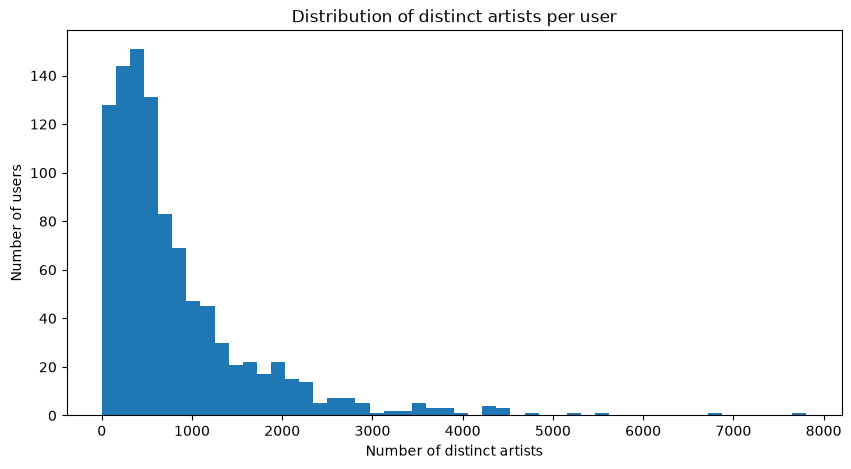

In [27]:
plt.figure(figsize=(10, 5))

plt.hist(
    user_stats["n_artists"],
    bins=50
)

plt.xlabel("Number of distinct artists")
plt.ylabel("Number of users")
plt.title("Distribution of distinct artists per user")

plt.show()

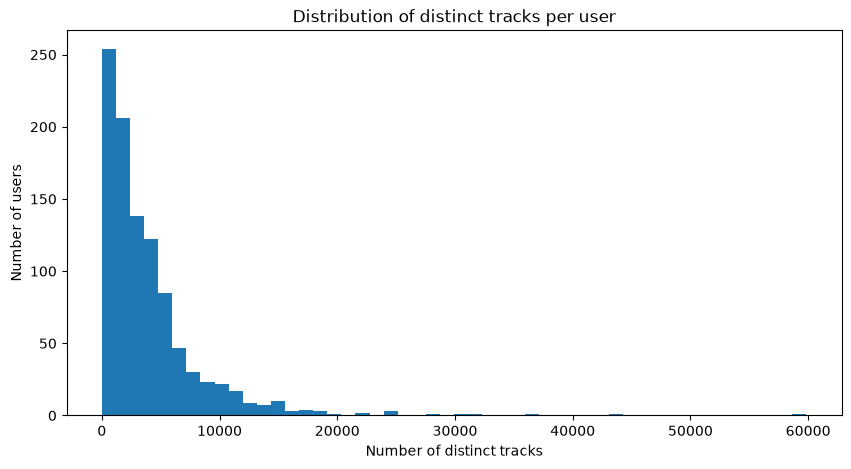

In [28]:
plt.figure(figsize=(10, 5))

plt.hist(
    user_stats["n_tracks"],
    bins=50
)

plt.xlabel("Number of distinct tracks")
plt.ylabel("Number of users")
plt.title("Distribution of distinct tracks per user")

plt.show()

In [29]:
user_stats["events_per_artist"] = (
    user_stats["n_events"] / user_stats["n_artists"]
)

user_stats["events_per_track"] = (
    user_stats["n_events"] / user_stats["n_tracks"]
)

user_stats[
    ["n_events", "n_artists", "n_tracks", "events_per_artist", "events_per_track"]
].describe()

,n_events,n_artists,n_tracks,events_per_artist,events_per_track
count,992.000000,992.000000,992.000000,992.000000,992.000000
mean,19305.310484,826.663306,3995.151210,27.823788,5.097393
std,23210.400389,860.361005,4682.570444,33.139574,5.248750
min,2.000000,1.000000,2.000000,1.000000,1.000000
25%,3774.250000,286.750000,1158.250000,8.012828,2.155494
50%,11551.000000,546.500000,2717.500000,17.894220,3.624891
75%,25707.750000,1053.500000,5170.000000,36.043590,6.191358
max,183103.000000,7809.000000,59850.000000,332.455357,89.507212


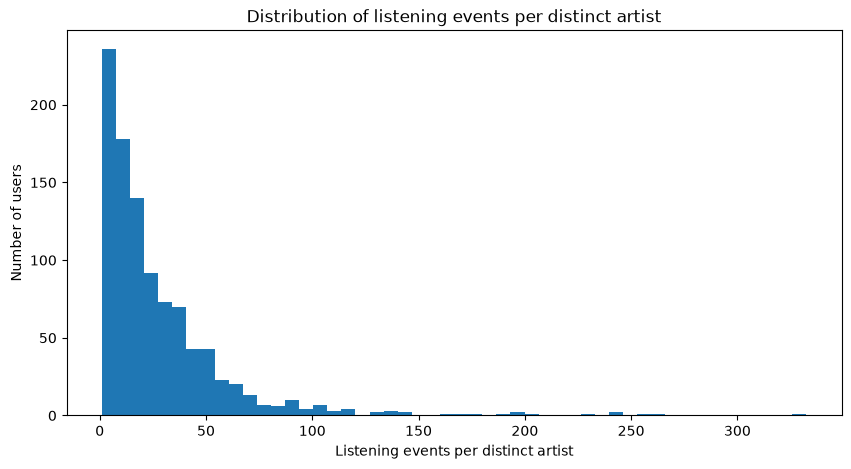

In [30]:
plt.figure(figsize=(10, 5))

plt.hist(
    user_stats["events_per_artist"],
    bins=50
)

plt.xlabel("Listening events per distinct artist")
plt.ylabel("Number of users")
plt.title("Distribution of listening events per distinct artist")

plt.show()

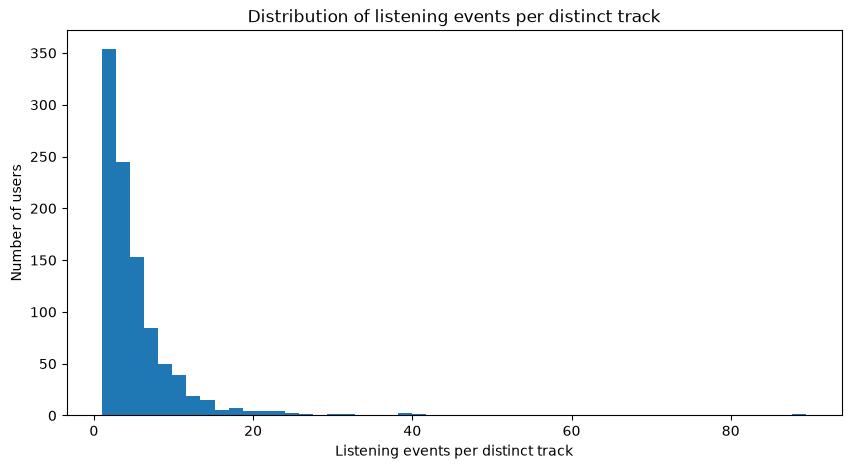

In [31]:
plt.figure(figsize=(10, 5))

plt.hist(
    user_stats["events_per_track"],
    bins=50
)

plt.xlabel("Listening events per distinct track")
plt.ylabel("Number of users")
plt.title("Distribution of listening events per distinct track")

plt.show()

In [ ]:
## 5. Global artist and track popularity

The global popularity distribution of artists and tracks is analyzed to characterize the concentration of listening activity across the catalog.

This analysis is relevant for the recommendation task because a highly concentrated popularity distribution can favor popular content and reduce exposure to less frequently consumed artists and tracks. It also provides a basis for the analysis of novelty, catalog coverage, and popularity-based recommendation baselines.

In [32]:
from collections import Counter

artist_play_count = Counter()
track_play_count = Counter()

with open(LISTENING_FILE, "r", encoding="utf-8", errors="replace") as f:
    for line in f:
        user_id, timestamp, artist_id, artist_name, track_id, track_name = (
            line.rstrip("\n\r").split("\t")
        )

        # Use IDs when available; otherwise fall back to names
        artist_key = artist_id if artist_id else f"name::{artist_name}"
        track_key = track_id if track_id else f"name::{artist_name}::{track_name}"

        artist_play_count[artist_key] += 1
        track_play_count[track_key] += 1

print("Unique artist entities:", len(artist_play_count))
print("Unique track entities:", len(track_play_count))

Unique artist entities: 176892
Unique track entities: 1505209


In [33]:
artist_popularity = pd.Series(
    artist_play_count,
    name="n_events"
)

artist_popularity.describe()

count    176892.000000
mean        108.263053
std        1108.392290
min           1.000000
25%           1.000000
50%           4.000000
75%          17.000000
max      115209.000000
Name: n_events, dtype: float64

In [34]:
track_popularity = pd.Series(
    track_play_count,
    name="n_events"
)

track_popularity.describe()

count    1.505209e+06
mean     1.272306e+01
std      5.323187e+01
min      1.000000e+00
25%      1.000000e+00
50%      2.000000e+00
75%      7.000000e+00
max      3.992000e+03
Name: n_events, dtype: float64

In [35]:
print("Top 20 artists:")
display(
    artist_popularity
    .sort_values(ascending=False)
    .head(20)
)

Top 20 artists:


a74b1b7f-71a5-4011-9441-d0b5e4122711    115209
b10bbbfc-cf9e-42e0-be17-e2c3e1d2600d    100338
b7ffd2af-418f-4be2-bdd1-22f8b48613da     84421
9c9f1380-2516-4fc9-a3e6-f9f61941d090     63346
cc197bad-dc9c-440d-a5b5-d52ba2e14234     62251
8538e728-ca0b-4321-b7e5-cff6565dd4c0     59910
83d91898-7763-47d7-b03b-b92132375c47     58561
0039c7ae-e1a7-4a7d-9b49-0cbc716821a6     58083
847e8284-8582-4b0e-9c26-b042a4f49e57     53518
03ad1736-b7c9-412a-b442-82536d63a5c4     50278
69ee3720-a7cb-4402-b48d-a02c366f2bcf     50207
45a663b5-b1cb-4a91-bff6-2bef7bbfdd76     49471
5441c29d-3602-4898-b1a1-b77fa23b8e50     49102
95e1ead9-4d31-4808-a7ac-32c3614c116b     48457
164f0d73-1234-4e2c-8743-d77bf2191051     46864
f6f2326f-6b25-4170-b89d-e235b25508e8     46078
40f5d9e4-2de7-4f2d-ad41-e31a9a9fea27     45687
8bfac288-ccc5-448d-9573-c33ea2aa5c30     45593
65f4f0c5-ef9e-490c-aee3-909e7ae6b2ab     44156
b23e8a63-8f47-4882-b55b-df2c92ef400e     43027
Name: n_events, dtype: int64

In [36]:
print("Top 20 tracks:")
display(
    track_popularity
    .sort_values(ascending=False)
    .head(20)
)

Top 20 tracks:


db16d0b3-b8ce-4aa8-a11a-e4d53cc7f8a6    3992
7f1f45c0-0101-49e9-8d69-23951d271163    3663
9e2ad5bc-c6f9-40d2-a36f-3122ee2072a3    3534
ff1e3e1a-f6e8-4692-b426-355880383bb6    3483
4e17b118-70a6-4c1f-b326-b4ce91fd3fad    3479
db4c9220-df76-4b42-b6f5-8bf52cc80f77    3156
60e94685-0481-4d3d-bd84-11c389d9b2a5    3060
f874c752-65bc-4d50-ac7e-932243ae9f02    3048
bd782340-6fa5-4b52-aa5a-ceafb9bc0340    3004
4ad08552-6c35-49ed-bcc6-6822c8f9dfd8    2998
6c450822-41ca-444e-8be5-10ee5a9ea53a    2989
153d8ca0-dc23-4548-b64f-2c49db7f30db    2950
f3bba4cd-8018-468b-902e-bc8f029593e5    2948
a5741d3d-c925-4070-8a83-910d23eb33d4    2947
40f04250-6d23-4f88-902c-94ef1a1dd3ed    2945
1001f481-e93e-4107-b640-cf289a122335    2906
e6d80ec5-85b3-4900-8e52-f83e9bf16852    2826
72c6b4d3-71a8-4c70-bf50-da11c0149089    2696
a73e9515-0d9b-480d-a7c0-188aa566522d    2670
72e52e92-c273-4b19-9821-5f812484d76d    2667
Name: n_events, dtype: int64

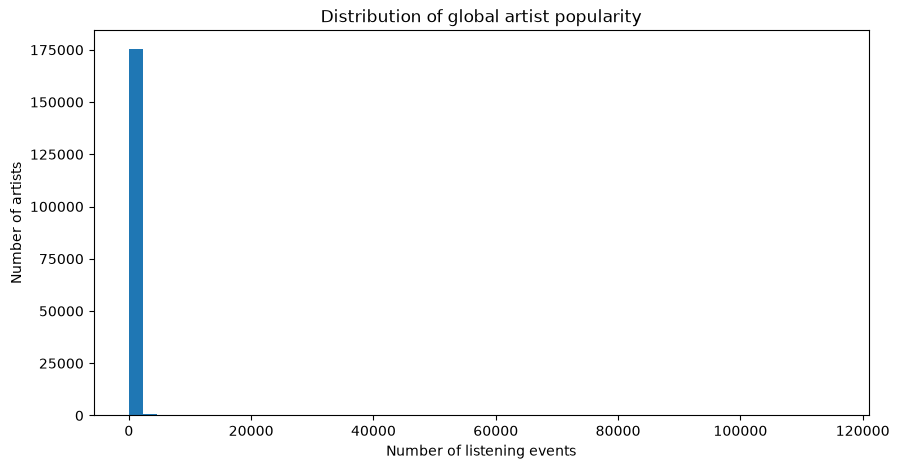

In [37]:
plt.figure(figsize=(10, 5))

plt.hist(
    artist_popularity,
    bins=50
)

plt.xlabel("Number of listening events")
plt.ylabel("Number of artists")
plt.title("Distribution of global artist popularity")

plt.show()

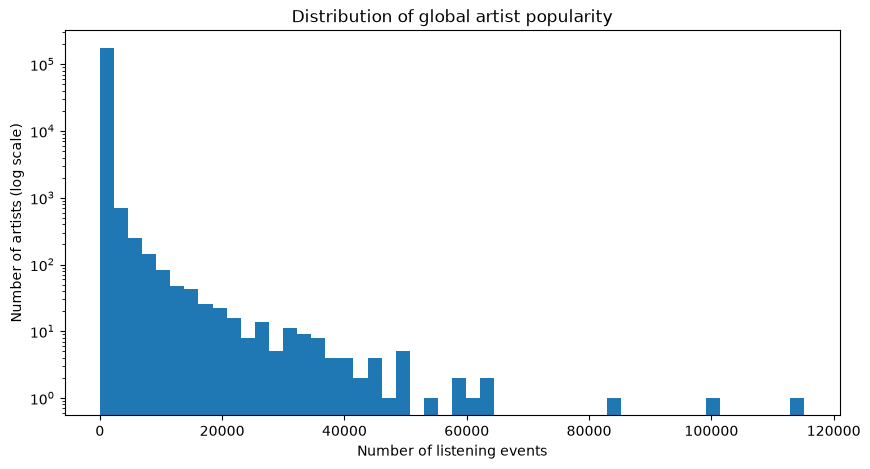

In [38]:
plt.figure(figsize=(10, 5))

plt.hist(
    artist_popularity,
    bins=50,
    log=True
)

plt.xlabel("Number of listening events")
plt.ylabel("Number of artists (log scale)")
plt.title("Distribution of global artist popularity")

plt.show()

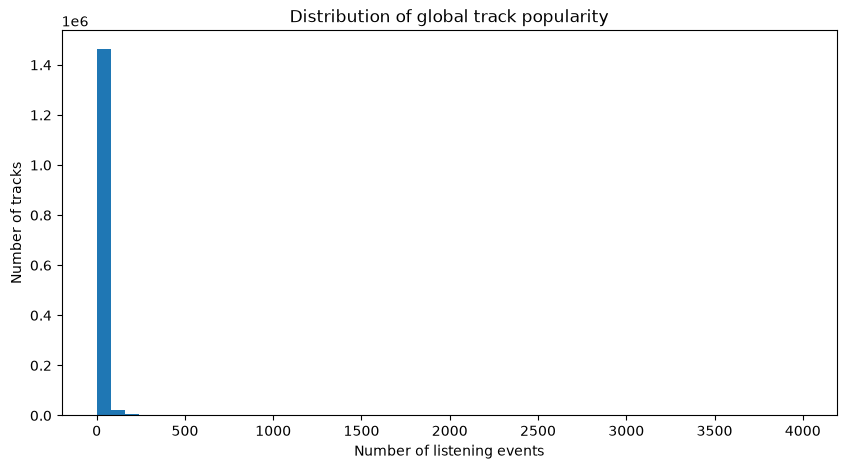

In [40]:
plt.figure(figsize=(10, 5))

plt.hist(
    track_popularity,
    bins=50
)

plt.xlabel("Number of listening events")
plt.ylabel("Number of tracks")
plt.title("Distribution of global track popularity")

plt.show()

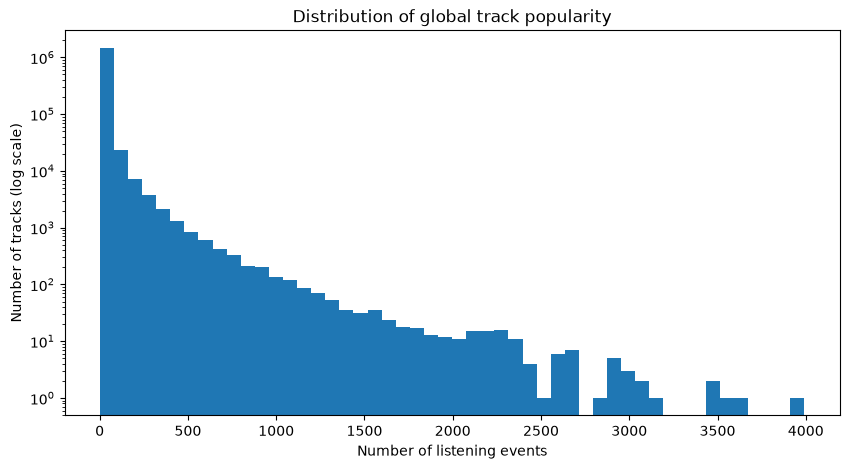

In [41]:
plt.figure(figsize=(10, 5))

plt.hist(
    track_popularity,
    bins=50,
    log=True
)

plt.xlabel("Number of listening events")
plt.ylabel("Number of tracks (log scale)")
plt.title("Distribution of global track popularity")

plt.show()

In [ ]:
## 6. Popularity concentration

The concentration of listening activity is analyzed by measuring the share of total interactions generated by the most popular artists and tracks.

This analysis quantifies the extent to which listening activity is concentrated in a small portion of the catalog and provides a more precise characterization of the long-tail structure observed in the previous analysis.

In [42]:
artist_sorted = artist_popularity.sort_values(ascending=False)

artist_total_events = artist_sorted.sum()

artist_concentration = pd.DataFrame({
    "top_percentage": [1, 5, 10, 20, 50],
    "n_artists": [
        max(1, int(len(artist_sorted) * p / 100))
        for p in [1, 5, 10, 20, 50]
    ]
})

artist_concentration["share_of_events"] = [
    artist_sorted.head(n).sum() / artist_total_events
    for n in artist_concentration["n_artists"]
]

artist_concentration

,top_percentage,n_artists,share_of_events
0,1,1768,0.627254
1,5,8844,0.854062
2,10,17689,0.919006
3,20,35378,0.962133
4,50,88446,0.991977


In [43]:
track_sorted = track_popularity.sort_values(ascending=False)

track_total_events = track_sorted.sum()

track_concentration = pd.DataFrame({
    "top_percentage": [1, 5, 10, 20, 50],
    "n_tracks": [
        max(1, int(len(track_sorted) * p / 100))
        for p in [1, 5, 10, 20, 50]
    ]
})

track_concentration["share_of_events"] = [
    track_sorted.head(n).sum() / track_total_events
    for n in track_concentration["n_tracks"]
]

track_concentration

,top_percentage,n_tracks,share_of_events
0,1,15052,0.318500
1,5,75260,0.586175
2,10,150520,0.711172
3,20,301041,0.828695
4,50,752604,0.948901


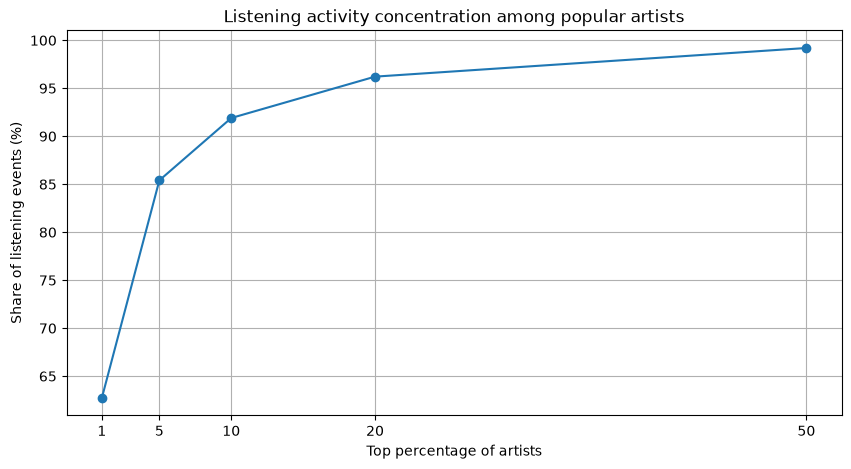

In [44]:
plt.figure(figsize=(10, 5))

plt.plot(
    artist_concentration["top_percentage"],
    artist_concentration["share_of_events"] * 100,
    marker="o"
)

plt.xlabel("Top percentage of artists")
plt.ylabel("Share of listening events (%)")
plt.title("Listening activity concentration among popular artists")

plt.xticks([1, 5, 10, 20, 50])
plt.grid(True)

plt.show()

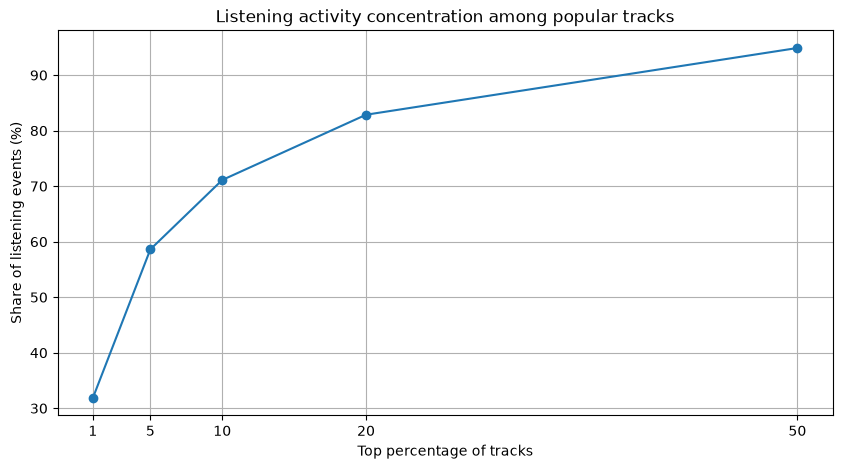

In [45]:
plt.figure(figsize=(10, 5))

plt.plot(
    track_concentration["top_percentage"],
    track_concentration["share_of_events"] * 100,
    marker="o"
)

plt.xlabel("Top percentage of tracks")
plt.ylabel("Share of listening events (%)")
plt.title("Listening activity concentration among popular tracks")

plt.xticks([1, 5, 10, 20, 50])
plt.grid(True)

plt.show()

In [ ]:
## 7. Listening repetition and familiarity

The distribution of repeated listening behavior is analyzed at the user level to characterize how strongly users concentrate their listening activity on previously observed artists and tracks.

This analysis is relevant to the music discovery problem because recommendation systems must balance the exploitation of familiar preferences with the exploration of less familiar content.

In [46]:
user_stats["artist_repetition_rate"] = (
    1 - user_stats["n_artists"] / user_stats["n_events"]
)

user_stats["track_repetition_rate"] = (
    1 - user_stats["n_tracks"] / user_stats["n_events"]
)

user_stats[
    [
        "artist_repetition_rate",
        "track_repetition_rate"
    ]
].describe()

,artist_repetition_rate,track_repetition_rate
count,992.000000,992.000000
mean,0.885690,0.664859
std,0.161416,0.226125
min,0.000000,0.000000
25%,0.875199,0.536069
50%,0.944116,0.724130
75%,0.972256,0.838485
max,0.996992,0.988828


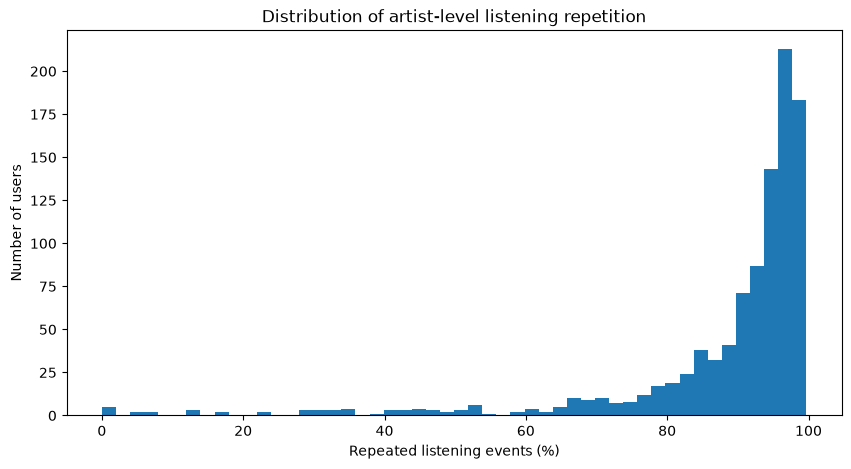

In [47]:
plt.figure(figsize=(10, 5))

plt.hist(
    user_stats["artist_repetition_rate"] * 100,
    bins=50
)

plt.xlabel("Repeated listening events (%)")
plt.ylabel("Number of users")
plt.title("Distribution of artist-level listening repetition")

plt.show()

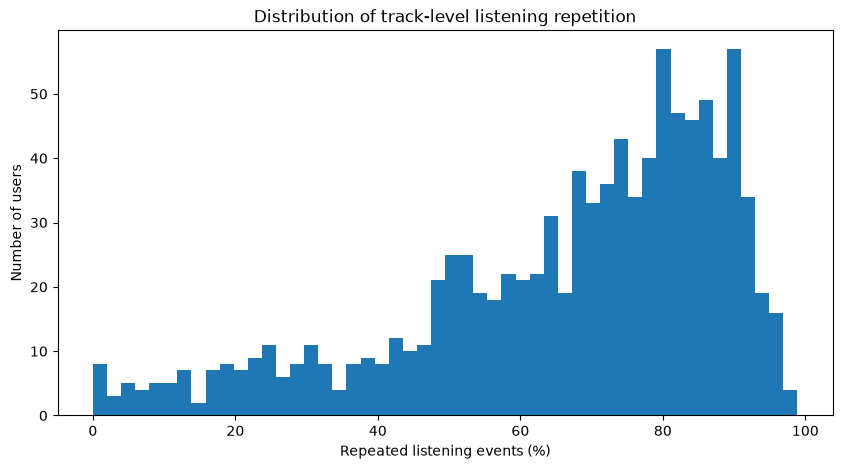

In [48]:
plt.figure(figsize=(10, 5))

plt.hist(
    user_stats["track_repetition_rate"] * 100,
    bins=50
)

plt.xlabel("Repeated listening events (%)")
plt.ylabel("Number of users")
plt.title("Distribution of track-level listening repetition")

plt.show()

In [ ]:
## 8. Concentration of listening within user histories

The concentration of listening activity within individual user histories is analyzed by measuring the share of interactions generated by the most frequently listened artists.

Unlike global popularity concentration, this analysis focuses on each user's personal listening profile. It helps characterize how strongly individual preferences are concentrated and provides further evidence for the exploitation component of the recommendation problem.

In [50]:
from collections import defaultdict

user_artist_events = defaultdict(Counter)

with open(LISTENING_FILE, "r", encoding="utf-8", errors="replace") as f:
    for line in f:
        (
            user_id,
            timestamp,
            artist_id,
            artist_name,
            track_id,
            track_name
        ) = line.rstrip("\n\r").split("\t")

        artist_key = artist_id if artist_id else f"name::{artist_name}"

        user_artist_events[user_id][artist_key] += 1

In [51]:
concentration_rows = []

for user_id, artist_counts in user_artist_events.items():

    sorted_counts = sorted(
        artist_counts.values(),
        reverse=True
    )

    total_events = sum(sorted_counts)
    n_artists = len(sorted_counts)

    row = {"user_id": user_id}

    for percentage in [1, 5, 10, 20]:
        n_top = max(
            1,
            int(np.ceil(n_artists * percentage / 100))
        )

        row[f"top_{percentage}_share"] = (
            sum(sorted_counts[:n_top]) / total_events
        )

    concentration_rows.append(row)

user_artist_concentration = pd.DataFrame(concentration_rows)

user_artist_concentration.describe()

,top_1_share,top_5_share,top_10_share,top_20_share
count,992.000000,992.000000,992.000000,992.000000
mean,0.227561,0.483473,0.629290,0.773122
std,0.112037,0.141374,0.143998,0.128835
min,0.016129,0.064516,0.111111,0.200000
25%,0.155525,0.401445,0.557926,0.724821
50%,0.208365,0.495753,0.647718,0.800794
75%,0.283120,0.569113,0.721847,0.857480
max,0.916667,0.945562,0.972096,0.989096


In [52]:
user_artist_concentration[
    [
        "top_1_share",
        "top_5_share",
        "top_10_share",
        "top_20_share"
    ]
].mean()

top_1_share     0.227561
top_5_share     0.483473
top_10_share    0.629290
top_20_share    0.773122
dtype: float64

In [53]:
user_artist_concentration[
    [
        "top_1_share",
        "top_5_share",
        "top_10_share",
        "top_20_share"
    ]
].median()

top_1_share     0.208365
top_5_share     0.495753
top_10_share    0.647718
top_20_share    0.800794
dtype: float64

In [55]:
mean_concentration = (
    user_artist_concentration[
        [
            "top_1_share",
            "top_5_share",
            "top_10_share",
            "top_20_share"
        ]
    ]
    .mean()
    .reset_index()
)

mean_concentration.columns = [
    "group",
    "share"
]

mean_concentration["percentage"] = [
    1, 5, 10, 20
]

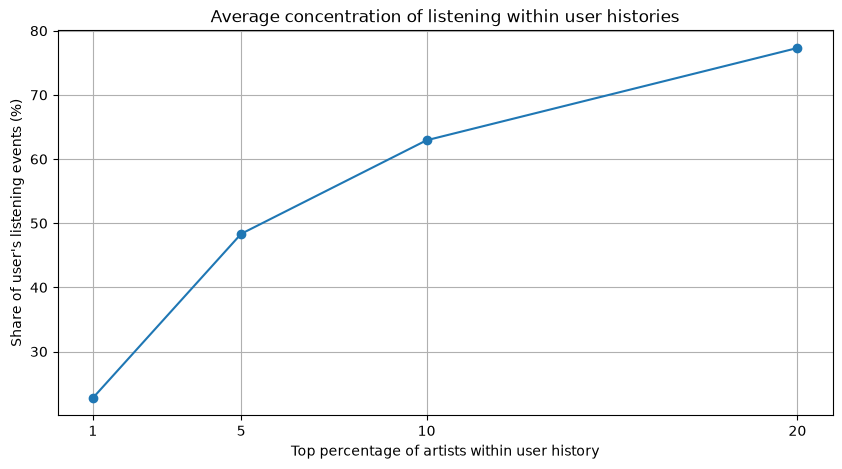

In [56]:
plt.figure(figsize=(10, 5))

plt.plot(
    mean_concentration["percentage"],
    mean_concentration["share"] * 100,
    marker="o"
)

plt.xlabel("Top percentage of artists within user history")
plt.ylabel("Share of user's listening events (%)")
plt.title("Average concentration of listening within user histories")

plt.xticks([1, 5, 10, 20])
plt.grid(True)

plt.show()

In [ ]:
## 9. Temporal analysis

The temporal distribution of listening events is analyzed to characterize the observation period of the dataset and the temporal activity of users.

This analysis is particularly relevant for the sequential recommendation setting, where historical interactions must precede future interactions. The temporal structure will therefore inform the design of the training, validation, and test periods.

In [61]:
year_event_count = Counter()

with open(LISTENING_FILE, "r", encoding="utf-8", errors="replace") as f:
    for line in f:
        fields = line.rstrip("\n\r").split("\t")
        timestamp = pd.Timestamp(fields[1])

        year_event_count[timestamp.year] += 1

year_events = pd.Series(
    year_event_count
).sort_index()

year_events

2005    1070656
2006    4255308
2007    5358216
2008    5929147
2009    2537539
2010          1
2013          1
dtype: int64

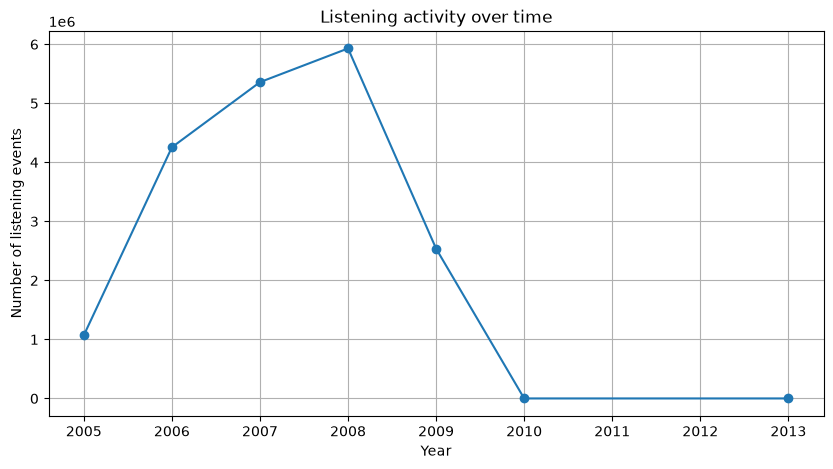

In [62]:
plt.figure(figsize=(10, 5))

plt.plot(
    year_events.index,
    year_events.values,
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Number of listening events")
plt.title("Listening activity over time")

plt.grid(True)

plt.show()

In [65]:
month_event_count = Counter()

with open(LISTENING_FILE, "r", encoding="utf-8", errors="replace") as f:
    for line in f:
        fields = line.rstrip("\n\r").split("\t")
        timestamp = pd.Timestamp(fields[1])

        month_event_count[
            timestamp.to_period("M")
        ] += 1

month_events = pd.Series(
    month_event_count
).sort_index()

month_events.head()

C:\Users\dales\AppData\Local\Temp\ipykernel_16480\3112975387.py:9: UserWarning: Converting to Period representation will drop timezone information.
  timestamp.to_period("M")


2005-02    24690
2005-03    49273
2005-04    74085
2005-05    69549
2005-06    81691
Freq: M, dtype: int64

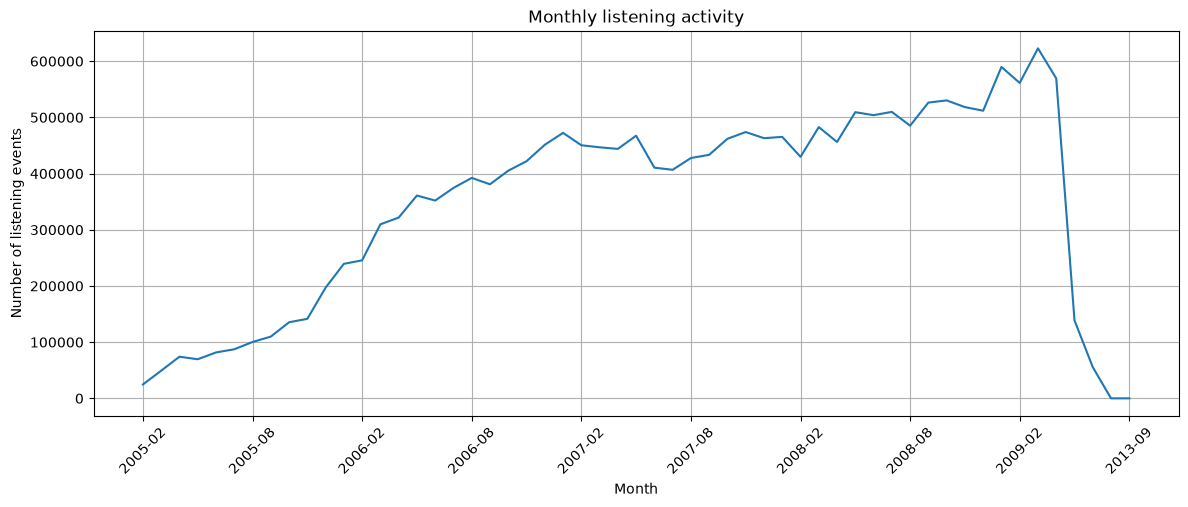

In [66]:
plt.figure(figsize=(14, 5))

plt.plot(
    month_events.index.astype(str),
    month_events.values
)

plt.xlabel("Month")
plt.ylabel("Number of listening events")
plt.title("Monthly listening activity")

plt.xticks(
    range(0, len(month_events), 6),
    month_events.index.astype(str)[::6],
    rotation=45
)

plt.grid(True)

plt.show()

In [67]:
user_stats["history_duration_days"] = (
    user_stats["last_timestamp"] -
    user_stats["first_timestamp"]
).dt.total_seconds() / (24 * 3600)

user_stats["history_duration_days"].describe()

count     992.000000
mean      877.876361
std       425.931350
min         5.814965
25%       564.914138
50%       925.626024
75%      1196.952214
max      2291.866701
Name: history_duration_days, dtype: float64

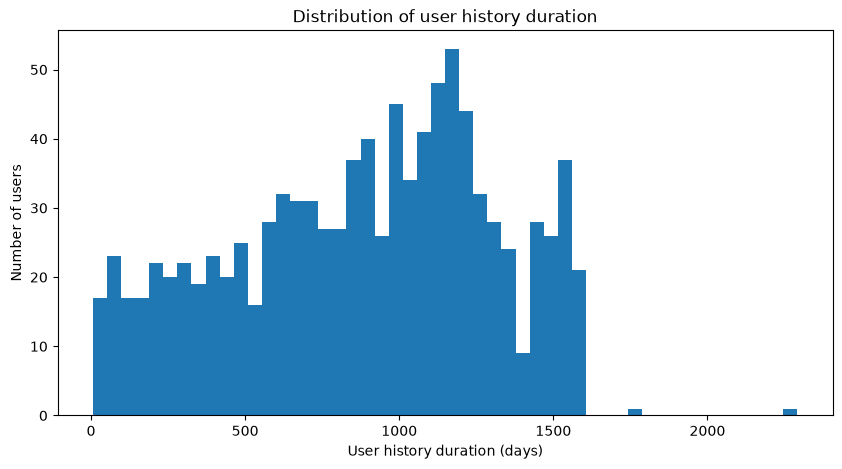

In [68]:
plt.figure(figsize=(10, 5))

plt.hist(
    user_stats["history_duration_days"],
    bins=50
)

plt.xlabel("User history duration (days)")
plt.ylabel("Number of users")
plt.title("Distribution of user history duration")

plt.show()

In [ ]:
## 10. Missing IDs and item identity

The Last.fm dataset contains listening events for which artist or track identifiers are missing.

Since the recommendation framework requires a consistent definition of artists and tracks, this section analyzes missing identifiers and checks whether textual names can be used as fallback keys.

The objective is to determine a reliable representation of artists and tracks before defining the candidate items and contextual bandit arms.

In [69]:
missing_counts = Counter()

total_events = 0

with open(LISTENING_FILE, "r", encoding="utf-8", errors="replace") as f:
    for line in f:
        (
            user_id,
            timestamp,
            artist_id,
            artist_name,
            track_id,
            track_name
        ) = line.rstrip("\n\r").split("\t")

        total_events += 1

        if not artist_id:
            missing_counts["artist_id"] += 1

        if not track_id:
            missing_counts["track_id"] += 1

        if not artist_name:
            missing_counts["artist_name"] += 1

        if not track_name:
            missing_counts["track_name"] += 1

missing_summary = pd.DataFrame({
    "missing_count": missing_counts,
})

missing_summary["percentage"] = (
    missing_summary["missing_count"] / total_events * 100
)

missing_summary

,missing_count,percentage
track_id,2168588,11.323706
artist_id,602166,3.144327


In [70]:
missing_artist_examples = []
missing_track_examples = []

with open(LISTENING_FILE, "r", encoding="utf-8", errors="replace") as f:
    for line in f:
        (
            user_id,
            timestamp,
            artist_id,
            artist_name,
            track_id,
            track_name
        ) = line.rstrip("\n\r").split("\t")

        if not artist_id and len(missing_artist_examples) < 20:
            missing_artist_examples.append(
                (artist_name, track_name)
            )

        if not track_id and len(missing_track_examples) < 20:
            missing_track_examples.append(
                (artist_name, track_name)
            )

print("Esempi di eventi con artist_id mancante:")
for x in missing_artist_examples:
    print(x)

print("\nEsempi di eventi con track_id mancante:")
for x in missing_track_examples:
    print(x)

Esempi di eventi con artist_id mancante:
('Rocket Empire', 'Simmer Down Jammie')
('Rocket Empire', 'Simmer Down Jammie')
('Rocket Empire', 'Simmer Down Jammie')
('Nicken', 'Lifeb')
('Ivan Enot', 'Grooves Of The Heart')
('Rocket Empire', 'Simmer Down Jammie')
('Nicken', 'Lifeb')
('Ivan Enot', 'Grooves Of The Heart')
('Rocket Empire', 'Simmer Down Jammie')
('Nicken', 'Lifeb')
('Ivan Enot', 'Grooves Of The Heart')
('Rocket Empire', 'Simmer Down Jammie')
('Nicken', 'Lifeb')
('Ivan Enot', 'Grooves Of The Heart')
('Agustin Pereyra Lucena', 'Bossa Cuasi Nova')
('Agustin Pereyra Lucena', 'Verbo Amar')
('Designed People', 'Breaking News')
('Designed People', 'Melo Feat. Pudgee')
('Designed People', 'Radio 808 Mars')
('Designed People', 'Breathe Feat. Monday Michiru')

Esempi di eventi con track_id mancante:
('Deep Dish', 'Fuck Me Im Famous (Pacha Ibiza)-09-28-2007')
('坂本龍一', 'Composition 0919 (Live_2009_4_15)')
('坂本龍一', 'Mc2 (Live_2009_4_15)')
('坂本龍一', 'Hibari (Live_2009_4_15)')
('坂本龍一', 'Mc1 (

In [71]:
artist_name_to_ids = defaultdict(set)

with open(LISTENING_FILE, "r", encoding="utf-8", errors="replace") as f:
    for line in f:
        (
            user_id,
            timestamp,
            artist_id,
            artist_name,
            track_id,
            track_name
        ) = line.rstrip("\n\r").split("\t")

        if artist_id and artist_name:
            artist_name_to_ids[artist_name].add(artist_id)

ambiguous_artist_names = {
    name: ids
    for name, ids in artist_name_to_ids.items()
    if len(ids) > 1
}

print("Artist names associati a più artist_id:", len(ambiguous_artist_names))

list(ambiguous_artist_names.items())[:20]

Artist names associati a più artist_id: 2295


[('Karma',
  {'7f98a6aa-2d17-42c3-b9af-e47e987edf6b',
   'e200ef60-9626-49ed-b761-864acef70d2a',
   'f0922a1b-ddc4-4eef-aa80-ff8975e05514',
   'f79a3132-5f5e-4583-b168-16cfc893bba0',
   'f945fc79-fb9e-4e3e-b60a-f4a90f5a6d38'}),
 ('Clark',
  {'292f77b4-3a9f-4cbb-8be4-b4a1367464f4',
   'bae7f609-bd83-4910-b07e-57ce317d46af',
   'eab8228c-a9c8-4ddb-a93d-ffca74a379bf'}),
 ('Home & Garden',
  {'4527a954-4d1d-4970-b389-d47e59e59713',
   'c2fc3098-b9a5-41ab-b897-e6d67b097dfa'}),
 ('Moby',
  {'32a92586-6f9f-4882-b168-97fd60a99b6d',
   '8970d868-0723-483b-a75b-51088913d3d4'}),
 ('James Brown',
  {'1a04c478-a260-401d-acdf-ecd5951d3bc9',
   '20ff3303-4fe2-4a47-a1b6-291e26aa3438'}),
 ('Helios',
  {'2dc4f948-ab1a-4b56-a05a-effe56f09c26',
   '50a32791-ee43-4c67-aabc-3dc65e4a9838',
   'dbb0b8b3-9a15-4915-80eb-a070dabdb1f3'}),
 ('Au',
  {'01515686-f67b-49a3-9b68-7b53914fc0a8',
   '383bdefa-29cd-4224-ba9e-112d5ace3a17'}),
 ('City',
  {'aa12d38f-a28c-4217-92d1-be8b615bd356',
   'bb1ee9fe-c5b9-46da-94ab-

In [72]:
track_name_to_ids = defaultdict(set)

with open(LISTENING_FILE, "r", encoding="utf-8", errors="replace") as f:
    for line in f:
        (
            user_id,
            timestamp,
            artist_id,
            artist_name,
            track_id,
            track_name
        ) = line.rstrip("\n\r").split("\t")

        if track_id and track_name:
            key = (artist_name, track_name)
            track_name_to_ids[key].add(track_id)

ambiguous_track_names = {
    key: ids
    for key, ids in track_name_to_ids.items()
    if len(ids) > 1
}

print(
    "Coppie (artist_name, track_name) associate a più track_id:",
    len(ambiguous_track_names)
)

list(ambiguous_track_names.items())[:20]

Coppie (artist_name, track_name) associate a più track_id: 4517


[(('Fleet Foxes', "He Doesn'T Know Why"),
  {'7f12b334-a7f3-4169-a234-b2b3e06f489c',
   'db8b4ec3-2c33-4d79-94f2-117ed0cd0c78'}),
 (('4Hero', 'Time (Feat. Ursula Rucker)'),
  {'04f8554e-fee2-4ab4-a538-c2fe63e90fdd',
   '7ba95180-f51c-49ab-b778-e23304f2e5a4'}),
 (('Enya', 'Stars And Midnight Blue'),
  {'2119e881-9d0a-4b02-bd2d-acfeafba88d4',
   '5b87f444-7d90-41bc-8d4d-99da986496c5'}),
 (('Moby', 'New York, New York (Feat. Debbie Harry)'),
  {'188ba6d6-43dc-4366-be63-ca19a8f453bb',
   'a5ae886d-1a25-4729-9ab3-09f70e910bee'}),
 (('Radiohead', 'Street Spirit (Fade Out)'),
  {'091eba5c-d8a8-44f3-a389-ccd90b6d1a73',
   'b10175e6-a3d7-4102-b97b-7f1b88c94cd3'}),
 (('Love Unlimited Orchestra', 'Strange Games And Things'),
  {'00c932ee-ea8d-4e01-877b-0a24a0954115',
   '784f180e-8546-4cbf-aa92-aaf3a8396cf7'}),
 (('Oasis', "I'M Outta Time"),
  {'719affb9-1886-4c34-bb96-39eb8d38f77e',
   'deff0452-a8b4-4f1f-b519-0e6fbc999f16'}),
 (('Oasis', '(Get Off Your) High Horse Lady'),
  {'800dbe39-20c8-4377

In [ ]:
### Impact of identifier ambiguity

The presence of multiple identifiers associated with the same textual name does not necessarily imply a substantial impact on the listening data.

We therefore quantify how many listening events involve ambiguous artist names or ambiguous track identities.

In [73]:
ambiguous_artist_names_set = set(ambiguous_artist_names.keys())
ambiguous_track_keys_set = set(ambiguous_track_names.keys())

ambiguous_artist_events = 0
ambiguous_track_events = 0

total_events = 0

with open(LISTENING_FILE, "r", encoding="utf-8", errors="replace") as f:
    for line in f:
        (
            user_id,
            timestamp,
            artist_id,
            artist_name,
            track_id,
            track_name
        ) = line.rstrip("\n\r").split("\t")

        total_events += 1

        if artist_name in ambiguous_artist_names_set:
            ambiguous_artist_events += 1

        if (artist_name, track_name) in ambiguous_track_keys_set:
            ambiguous_track_events += 1

print("Total events:", total_events)

print(
    "Events with ambiguous artist name:",
    ambiguous_artist_events,
    f"({ambiguous_artist_events / total_events * 100:.2f}%)"
)

print(
    "Events with ambiguous (artist_name, track_name):",
    ambiguous_track_events,
    f"({ambiguous_track_events / total_events * 100:.2f}%)"
)

Total events: 19150868
Events with ambiguous artist name: 1280046 (6.68%)
Events with ambiguous (artist_name, track_name): 479005 (2.50%)


In [ ]:
## 11. Interaction sparsity and cold-start

The recommendation problem is characterized by a large item catalog and a much smaller number of interactions per item.

This section analyzes the distribution of interactions across tracks and artists, with particular attention to rarely observed and cold-start items.

These statistics are relevant for defining the candidate generation strategy and for understanding the difficulty of discovering less popular music.

In [74]:
track_interaction_counts = pd.Series(
    list(track_play_count.values())
)

track_interaction_counts.describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

count    1.505209e+06
mean     1.272306e+01
std      5.323187e+01
min      1.000000e+00
25%      1.000000e+00
50%      2.000000e+00
75%      7.000000e+00
90%      2.300000e+01
95%      4.600000e+01
99%      1.850000e+02
max      3.992000e+03
dtype: float64

In [75]:
track_frequency_summary = pd.Series({
    "1 interaction": (track_interaction_counts == 1).sum(),
    "2 interactions": (track_interaction_counts == 2).sum(),
    "3-5 interactions": track_interaction_counts.between(3, 5).sum(),
    "6-10 interactions": track_interaction_counts.between(6, 10).sum(),
    "11-50 interactions": track_interaction_counts.between(11, 50).sum(),
    ">50 interactions": (track_interaction_counts > 50).sum(),
})

track_frequency_summary

1 interaction         526618
2 interactions        226747
3-5 interactions      287975
6-10 interactions     173758
11-50 interactions    221865
>50 interactions       68246
dtype: int64

In [76]:
track_frequency_percentage = (
    track_frequency_summary
    / len(track_interaction_counts)
    * 100
)

track_frequency_percentage

1 interaction         34.986371
2 interactions        15.064154
3-5 interactions      19.131895
6-10 interactions     11.543779
11-50 interactions    14.739814
>50 interactions       4.533988
dtype: float64

In [77]:
track_user_sets = defaultdict(set)

with open(LISTENING_FILE, "r", encoding="utf-8", errors="replace") as f:
    for line in f:
        (
            user_id,
            timestamp,
            artist_id,
            artist_name,
            track_id,
            track_name
        ) = line.rstrip("\n\r").split("\t")

        track_key = (
            track_id
            if track_id
            else f"name::{artist_name}::{track_name}"
        )

        track_user_sets[track_key].add(user_id)

track_user_counts = pd.Series({
    track: len(users)
    for track, users in track_user_sets.items()
})

track_user_counts.describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

count    1.505209e+06
mean     3.069960e+00
std      8.363426e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      2.000000e+00
90%      5.000000e+00
95%      1.000000e+01
99%      3.600000e+01
max      3.460000e+02
dtype: float64

In [78]:
track_user_frequency = pd.Series({
    "1 user": (track_user_counts == 1).sum(),
    "2 users": (track_user_counts == 2).sum(),
    "3-5 users": track_user_counts.between(3, 5).sum(),
    "6-10 users": track_user_counts.between(6, 10).sum(),
    "11-50 users": track_user_counts.between(11, 50).sum(),
    ">50 users": (track_user_counts > 50).sum(),
})

track_user_frequency

1 user         990355
2 users        200802
3-5 users      171211
6-10 users      70598
11-50 users     63335
>50 users        8908
dtype: int64